# Ridge Regression

 1. Feature Engineering
2. Prepare Training and Validation Data
3. Model Training and Evaluation
4. Visualize Model Predictions
5. Peak Demand Analysis

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
from src.build_features import build_features

features = build_features()

In [3]:
features.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 34589 entries, 2006-12-16 17:00:00 to 2010-11-26 21:00:00
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   target_kw        34085 non-null  float64
 1   hour             34589 non-null  int32  
 2   day_of_week      34589 non-null  int32  
 3   month            34589 non-null  int32  
 4   is_weekend       34589 non-null  int64  
 5   lag_24           34062 non-null  float64
 6   lag_168          33918 non-null  float64
 7   lag_1            34085 non-null  float64
 8   rolling_mean_24  32494 non-null  float64
dtypes: float64(5), int32(3), int64(1)
memory usage: 2.2 MB


In [4]:
features.tail(10)

,target_kw,hour,day_of_week,month,is_weekend,lag_24,lag_168,lag_1,rolling_mean_24
timestamp,,,,,,,,,
2010-11-26 12:00:00,1.490200,12,4,11,0,0.499733,1.390700,1.338900,1.150549
2010-11-26 13:00:00,1.612933,13,4,11,0,0.356233,1.594400,1.490200,1.083682
2010-11-26 14:00:00,1.407767,14,4,11,0,0.300667,1.521100,1.612933,1.012136
2010-11-26 15:00:00,0.876433,15,4,11,0,0.333000,1.622867,1.407767,0.963426
2010-11-26 16:00:00,1.067933,16,4,11,0,0.541800,1.469700,0.876433,0.949582
2010-11-26 17:00:00,1.725900,17,4,11,0,1.480100,0.824267,1.067933,0.930464
2010-11-26 18:00:00,1.573467,18,4,11,0,2.211600,1.018467,1.725900,0.936733
2010-11-26 19:00:00,1.659333,19,4,11,0,2.330467,1.249767,1.573467,0.971410
2010-11-26 20:00:00,1.163700,20,4,11,0,1.647833,1.665267,1.659333,0.943700


## Prepare Training and Validation Data

Remove rows with missing targets or features while preserving
chronological order.

In [5]:
model_df = features.dropna().copy()

train_df = model_df.loc[: "2008-12-31 23:00"]
val_df = model_df.loc["2009-01-01":"2009-12-31 23:00"]
test_df = model_df.loc["2010-01-01":]

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 16626
Validation: 8124
Test: 6861


## Separate features from targets

In [65]:
X_train = train_df.drop(columns=["target_kw"])
y_train = train_df["target_kw"]

X_val = val_df.drop(columns=["target_kw"])
y_val = val_df["target_kw"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

X_train shape: (16626, 8)
y_train shape: (16626,)
X_val shape: (8124, 8)
y_val shape: (8124,)


In [66]:
def encode_calendar(X):
    X = X.copy()

    # Cyclical encoding for day of week and month
    for col, period in [
        ("day_of_week", 7),
        ("month", 12),
    ]:
        angle = 2 * np.pi * X[col] / period

        X[f"{col}_sin"] = np.sin(angle)
        X[f"{col}_cos"] = np.cos(angle)

    # One-hot encoding for hour of day
    for hour in range(24):
        X[f"hour_{hour}"] = (
            X["hour"] == hour
        ).astype(int)

        # Hour and weekend interaction
        X[f"hour_{hour}_weekend"] = (
            X[f"hour_{hour}"] * X["is_weekend"]
        )

    return X.drop(
        columns=["hour", "day_of_week", "month"]
    )

X_train_encoded = encode_calendar(X_train)
X_val_encoded = encode_calendar(X_val)

X_train_encoded.head()

,is_weekend,lag_24,lag_168,lag_1,rolling_mean_24,day_of_week_sin,day_of_week_cos,month_sin,month_cos,hour_0,...,hour_19,hour_19_weekend,hour_20,hour_20_weekend,hour_21,hour_21_weekend,hour_22,hour_22_weekend,hour_23,hour_23_weekend
timestamp,,,,,,,,,,,,,,,,,,,,,
2006-12-23 18:00:00,1,2.686967,3.632200,5.452533,1.153442,-0.974928,-0.222521,-2.449294e-16,1.0,0,...,0,0,0,0,0,0,0,0,0,0
2006-12-23 19:00:00,1,3.938167,3.400233,3.879400,1.225985,-0.974928,-0.222521,-2.449294e-16,1.0,0,...,1,1,0,0,0,0,0,0,0,0
2006-12-23 20:00:00,1,3.536067,3.268567,4.117833,1.271764,-0.974928,-0.222521,-2.449294e-16,1.0,0,...,0,0,1,1,0,0,0,0,0,0
2006-12-23 21:00:00,1,4.548667,3.056467,4.181400,1.420364,-0.974928,-0.222521,-2.449294e-16,1.0,0,...,0,0,0,0,1,1,0,0,0,0
2006-12-23 22:00:00,1,3.065067,2.200133,3.288433,1.536397,-0.974928,-0.222521,-2.449294e-16,1.0,0,...,0,0,0,0,0,0,1,1,0,0


In [72]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

ridge_pipeline.fit(X_train_encoded, y_train)

print("Ridge Regression trained successfully!")

Ridge Regression trained successfully!


/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [73]:
ridge_predictions_raw = ridge_pipeline.predict(
    X_val_encoded
)

# Enforce non-negative electricity demand
ridge_predictions = np.maximum(
    ridge_predictions_raw, 0
)

print("First 5 predictions:")
print(ridge_predictions[:5])

print("\nFirst 5 actual values:")
print(y_val.iloc[:5].values)

First 5 predictions:
[0.56196249 0.52308329 0.52674421 0.55960952 0.58576115]

First 5 actual values:
[0.53493333 0.54046667 0.57536667 0.5265     0.5219    ]


/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


## Model Evaluation

Evaluate Ridge Regression against daily and weekly
seasonal-naive baselines using MAE and RMSE on
identical validation timestamps.

In [74]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create a comparison dataset
comparison = val_df[
    ["target_kw", "lag_1", "lag_24", "lag_168"]
].copy()

comparison["ridge"] = ridge_predictions

# Evaluate all three forecasting approaches
results = []

for model, column in [
    ("Hourly Naive", "lag_1"),
    ("Daily Naive", "lag_24"),
    ("Weekly Naive", "lag_168"),
    ("Ridge Regression", "ridge")
]:
    mae = mean_absolute_error(
        comparison["target_kw"],
        comparison[column]
    )

    rmse = np.sqrt(
        mean_squared_error(
            comparison["target_kw"],
            comparison[column]
        )
    )

    results.append({
        "Model": model,
        "MAE (kW)": mae,
        "RMSE (kW)": rmse
    })

results_df = pd.DataFrame(results)
results_df.sort_values("MAE (kW)")

,Model,MAE (kW),RMSE (kW)
3,Ridge Regression,0.370864,0.532377
0,Hourly Naive,0.431716,0.658933
2,Weekly Naive,0.565109,0.840827
1,Daily Naive,0.609805,0.899521


In [87]:
print("Minimum raw prediction:", ridge_predictions_raw.min())

print("Negative predictions before clipping:", (ridge_predictions_raw < 0).sum())

print("\nMinimum clipped prediction:", ridge_predictions.min())

print("Maximum clipped prediction:", ridge_predictions.max())

print("Negative predictions after clipping:", (ridge_predictions < 0).sum())

print("\nActual validation range:")
print("Minimum:", y_val.min())
print("Maximum:", y_val.max())

Minimum raw prediction: -0.05913444469484941
Negative predictions before clipping: 7

Minimum clipped prediction: 0.0
Maximum clipped prediction: 4.960289436352682
Negative predictions after clipping: 0

Actual validation range:
Minimum: 0.17973333333333336
Maximum: 5.2338000000000005


## Visualize Model Predictions

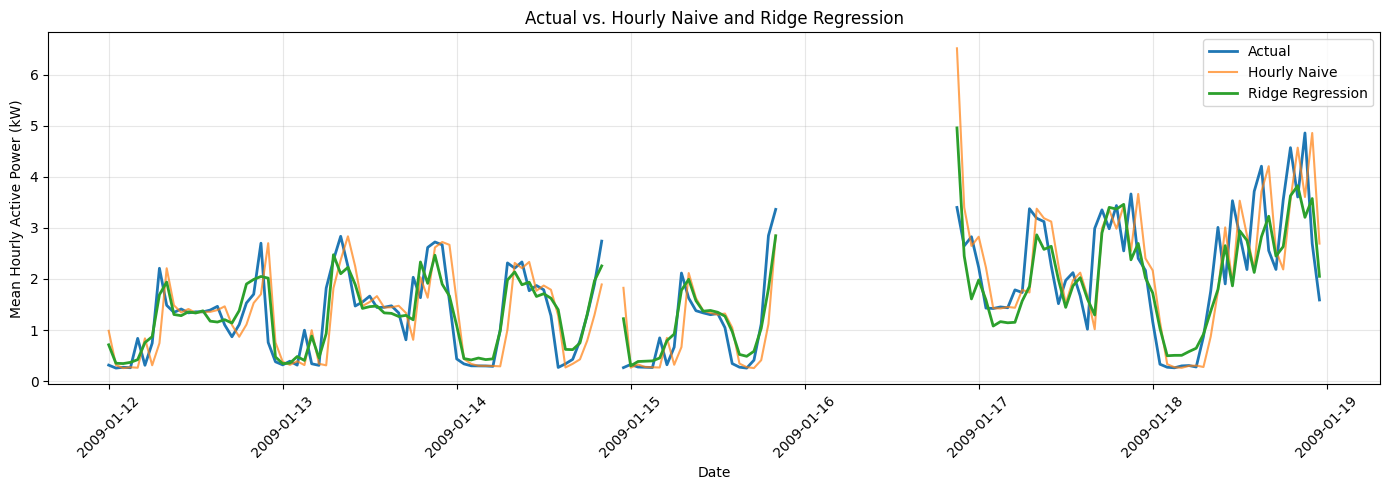

In [76]:
sample = comparison.loc["2009-01-12":"2009-01-18"]

sample = sample.asfreq("h")

plt.figure(figsize=(14, 5))

plt.plot(sample.index, sample["target_kw"], label="Actual", linewidth=2)

plt.plot(sample.index, sample["lag_1"], label="Hourly Naive", alpha=0.7)

plt.plot(sample.index, sample["ridge"], label="Ridge Regression", linewidth=2)

plt.title("Actual vs. Hourly Naive and Ridge Regression")
plt.xlabel("Date")
plt.ylabel("Mean Hourly Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [77]:
ridge_error = (
    comparison["target_kw"] - comparison["ridge"]
).abs()

hourly_error = (
    comparison["target_kw"] - comparison["lag_1"]
).abs()

ridge_win_rate = (ridge_error < hourly_error).mean()

print(f"Ridge win rate: {ridge_win_rate:.2%}")

Ridge win rate: 51.65%


## 5. Peak Demand Analysis

Investigate how Ridge Regression performs during the
highest electricity demand observations in validation.

In [78]:
peak_comparison = comparison.nlargest(10, "target_kw").copy()

peak_comparison["ridge_error"] = (peak_comparison["target_kw"] - peak_comparison["ridge"])

peak_comparison["hourly_error"] = (peak_comparison["target_kw"] - peak_comparison["lag_1"])

peak_comparison

,target_kw,lag_1,lag_24,lag_168,ridge,ridge_error,hourly_error
timestamp,,,,,,,
2009-02-11 18:00:00,5.233800,1.013400,1.303867,2.542400,1.409692,3.824108,4.220400
2009-04-12 21:00:00,5.133967,5.098300,2.738933,1.259500,3.807736,1.326230,0.035667
2009-11-22 20:00:00,5.115167,3.818933,3.538233,2.040500,3.370972,1.744195,1.296233
2009-04-12 20:00:00,5.098300,2.653167,4.145133,2.183467,2.652599,2.445701,2.445133
2009-01-24 11:00:00,5.073400,1.861733,1.592900,1.516567,1.828355,3.245045,3.211667
2009-01-31 17:00:00,5.072500,3.407433,3.019767,1.065167,2.899238,2.173262,1.665067
2009-01-18 21:00:00,4.860700,3.606900,3.665800,3.503933,3.208421,1.652279,1.253800
2009-11-03 20:00:00,4.830833,4.125833,2.753667,2.055633,3.507037,1.323796,0.705000
2009-02-22 17:00:00,4.829433,3.718800,0.506933,0.357133,2.852971,1.976462,1.110633


## Forecasting Error by Hour of Day

Compare Ridge Regression against hourly, daily, and
weekly naive baselines to identify when the model
improves forecasting accuracy.

In [79]:
hourly_errors = comparison.copy()

hourly_errors["hour"] = hourly_errors.index.hour

hourly_errors["ridge_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["ridge"]
).abs()

hourly_errors["hourly_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["lag_1"]
).abs()

hourly_errors["daily_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["lag_24"]
).abs()

hourly_errors["weekly_error"] = (
    hourly_errors["target_kw"] -
    hourly_errors["lag_168"]
).abs()

In [80]:
error_by_hour = hourly_errors.groupby("hour")[
    [
        "ridge_error",
        "hourly_error",
        "daily_error",
        "weekly_error"
    ]
].mean()

error_by_hour

,ridge_error,hourly_error,daily_error,weekly_error
hour,,,,
0,0.252097,0.341994,0.418389,0.348756
1,0.179374,0.178609,0.312050,0.297032
2,0.150059,0.138851,0.245778,0.233540
3,0.145714,0.123845,0.217616,0.224962
4,0.174665,0.164672,0.230513,0.250612
5,0.192854,0.186459,0.240556,0.251770
6,0.313075,0.439315,0.423781,0.409757
7,0.498139,0.830938,0.710324,0.591540
8,0.379826,0.490877,0.577303,0.555871


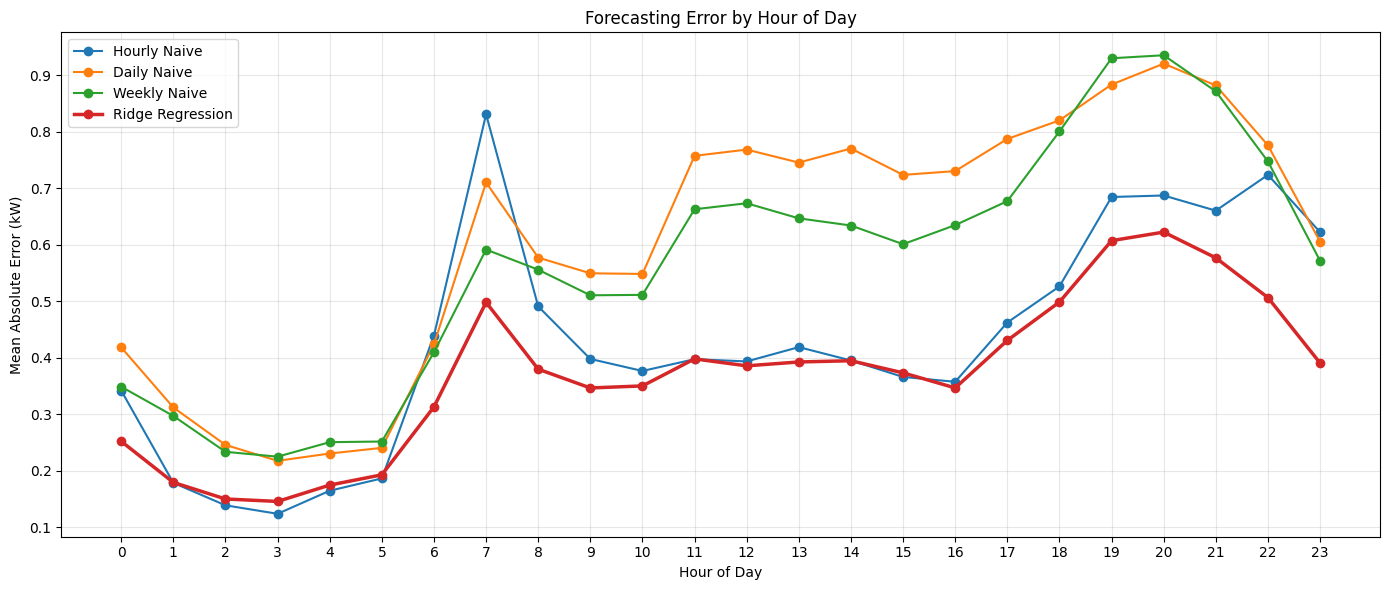

In [81]:
plt.figure(figsize=(14, 6))

plt.plot(
    error_by_hour.index,
    error_by_hour["hourly_error"],
    marker="o",
    label="Hourly Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["daily_error"],
    marker="o",
    label="Daily Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["weekly_error"],
    marker="o",
    label="Weekly Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["ridge_error"],
    marker="o",
    linewidth=2.5,
    label="Ridge Regression"
)

plt.title("Forecasting Error by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error (kW)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Forecasting Error by Weekday vs. Weekend

Compare Ridge Regression against the three naive
baselines across weekday and weekend hours.

Investigate whether Ridge improves forecasting during
the weekday morning demand peak, particularly at 7 AM.

In [82]:
weekday_errors = hourly_errors.copy()

weekday_errors["day_of_week"] = (
    weekday_errors.index.dayofweek
)

weekday_errors["is_weekend"] = (
    weekday_errors["day_of_week"] >= 5
)

weekday_errors.head()

,target_kw,lag_1,lag_24,lag_168,ridge,hour,ridge_error,hourly_error,daily_error,weekly_error,day_of_week,is_weekend
timestamp,,,,,,,,,,,,
2009-01-01 00:00:00,0.534933,0.575433,0.267567,1.842567,0.561962,0,0.027029,0.040500,0.267367,1.307633,3,False
2009-01-01 01:00:00,0.540467,0.534933,0.250600,0.873767,0.523083,1,0.017383,0.005533,0.289867,0.333300,3,False
2009-01-01 02:00:00,0.575367,0.540467,0.290900,0.267833,0.526744,2,0.048622,0.034900,0.284467,0.307533,3,False
2009-01-01 03:00:00,0.526500,0.575367,0.263967,0.271167,0.559610,3,0.033110,0.048867,0.262533,0.255333,3,False
2009-01-01 04:00:00,0.521900,0.526500,0.818533,0.291733,0.585761,4,0.063861,0.004600,0.296633,0.230167,3,False


In [83]:
error_by_day_type = weekday_errors.groupby(
    ["is_weekend", "hour"]
)[
    [
        "hourly_error",
        "daily_error",
        "weekly_error",
        "ridge_error"
    ]
].mean()

error_by_day_type

hourly_error  daily_error  weekly_error  ridge_error
is_weekend hour                                                      
False      0         0.330613     0.358161      0.258398     0.232704
           1         0.142655     0.257321      0.205111     0.146559
           2         0.114893     0.215748      0.177456     0.136395
           3         0.116166     0.189126      0.189529     0.135580
           4         0.168025     0.214527      0.229768     0.175139
           5         0.190838     0.219425      0.213619     0.189691
           6         0.531572     0.422317      0.452477     0.346705
           7         0.917641     0.672725      0.579702     0.472196
           8         0.498061     0.552205      0.521887     0.371675
           9         0.352135     0.555996      0.462578     0.304236
           10        0.316024     0.539214      0.465480     0.296503
           11        0.303800     0.661317      0.532764     0.309240
           12        0.319607     0.728371      0.595766     0.338376
           13        0.337636     0.709391      0.606527     0.333926
           14        0.297174     0.735685      0.551645     0.303480
           15        0.320746     0.632609      0.513754     0.325637
           16        0.280880     0.651517      0.508011     0.279981
           17        0.369977     0.692855      0.502634     0.351904
           18        0.477397     0.745994      0.685369     0.442496
           19        0.711476     0.869734      0.890891     0.595731
           20        0.690242     0.876260      0.894847     0.620943
           21        0.678454     0.792669      0.773311     0.568768
           22        0.716286     0.691057      0.658004     0.474481
           23        0.632713     0.477215      0.502703     0.378775
True       0         0.370623     0.569891      0.576049     0.300880
           1         0.269051     0.449717      0.528257     0.261919
           2         0.199118     0.321318      0.374616     0.184432
           3         0.143162     0.289280      0.314092     0.171206
           4         0.156309     0.270396      0.302613     0.173482
           5         0.175624     0.292840      0.346165     0.200679
           6         0.210100     0.427418      0.303615     0.229521
           7         0.614627     0.804128      0.621075     0.562860
           8         0.473429     0.638257      0.638404     0.399622
           9         0.513961     0.533140      0.632373     0.453943
           10        0.528810     0.571355      0.626449     0.485022
           11        0.631245     0.997242      0.987524     0.619556
           12        0.578704     0.868862      0.868090     0.504366
           13        0.622296     0.835989      0.747647     0.539528
           14        0.640939     0.857271      0.840668     0.623399
           15        0.481985     0.956676      0.824313     0.495264
           16        0.554739     0.933566      0.961172     0.518340
           17        0.703847     1.034135      1.133309     0.636636
           18        0.655846     1.016621      1.105507     0.647394
           19        0.616724     0.918425      1.029076     0.636444
           20        0.679836     1.030135      1.035683     0.626122
           21        0.616134     1.100871      1.112165     0.596659
           22        0.741922     0.985073      0.967632     0.585395
           23        0.597020     0.925344      0.743485     0.420512

In [84]:
weekday_profile = error_by_day_type.loc[False]

weekend_profile = error_by_day_type.loc[True]

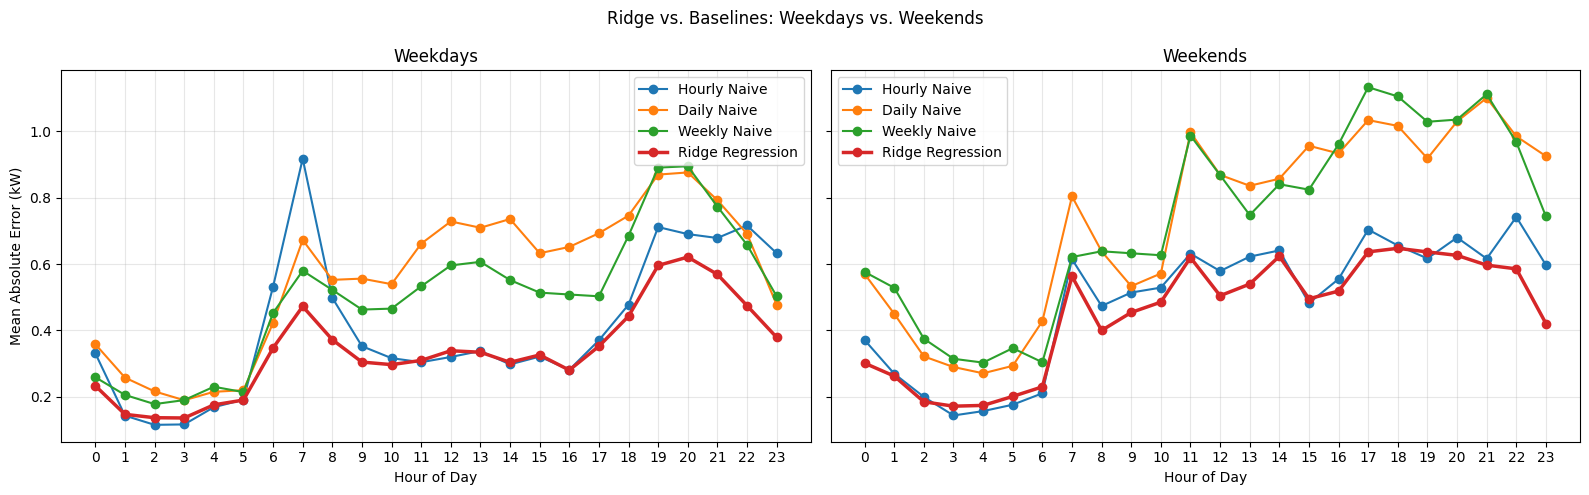

In [85]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

for ax, profile, title in [
    (axes[0], weekday_profile, "Weekdays"),
    (axes[1], weekend_profile, "Weekends")
]:
    ax.plot(
        profile.index,
        profile["hourly_error"],
        marker="o",
        label="Hourly Naive"
    )

    ax.plot(
        profile.index,
        profile["daily_error"],
        marker="o",
        label="Daily Naive"
    )

    ax.plot(
        profile.index,
        profile["weekly_error"],
        marker="o",
        label="Weekly Naive"
    )

    ax.plot(
        profile.index,
        profile["ridge_error"],
        marker="o",
        linewidth=2.5,
        label="Ridge Regression"
    )

    ax.set_title(title)
    ax.set_xlabel("Hour of Day")
    ax.set_xticks(range(24))
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Mean Absolute Error (kW)")

fig.suptitle(
    "Ridge vs. Baselines: Weekdays vs. Weekends"
)

plt.tight_layout()
plt.show()

In [86]:
error_by_day_type.loc[
    [(False, 7), (True, 7)],
    ["ridge_error", "hourly_error", "weekly_error"]
]

,,ridge_error,hourly_error,weekly_error
is_weekend,hour,,,
False,7,0.472196,0.917641,0.579702
True,7,0.562860,0.614627,0.621075


In [88]:
print("Raw Ridge MAE:",
      mean_absolute_error(y_val, ridge_predictions_raw))

print("Clipped Ridge MAE:",
      mean_absolute_error(y_val, ridge_predictions))

print("Raw Ridge RMSE:",
      np.sqrt(mean_squared_error(y_val, ridge_predictions_raw)))

print("Clipped Ridge RMSE:",
      np.sqrt(mean_squared_error(y_val, ridge_predictions)))

Raw Ridge MAE: 0.3708904275746497
Clipped Ridge MAE: 0.37086378803716646
Raw Ridge RMSE: 0.5323930738343481
Clipped Ridge RMSE: 0.532377205161041


## Hyperparameter Tuning

Evaluate the effect of Ridge regularization strength (alpha)
on validation forecasting performance while maintaining
the existing feature set, scaling, and nonnegative clipping.

In [89]:
alpha_values = [0.01, 0.1, 1.0, 10, 100, 1000]

tuning_results = []

for alpha in alpha_values:

    # Create a new pipeline for each alpha
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha))
    ])

    # Train the model
    pipeline.fit(X_train_encoded, y_train)

    # Generate predictions
    predictions = pipeline.predict(X_val_encoded)

    # Count negative predictions before clipping
    negative_count = (predictions < 0).sum()

    # Apply nonnegative clipping
    predictions = np.maximum(predictions, 0)

    # Evaluate performance
    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))

    # Save results
    tuning_results.append({
        "alpha": alpha,
        "MAE": mae,
        "RMSE": rmse,
        "negative_predictions": negative_count
    })

tuning_df = pd.DataFrame(tuning_results)

tuning_df

/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Volumes/External

,alpha,MAE,RMSE,negative_predictions
0,0.01,0.370863,0.532380,7
1,0.10,0.370863,0.532380,7
2,1.00,0.370864,0.532377,7
3,10.00,0.370868,0.532348,7
4,100.00,0.370923,0.532073,6
5,1000.00,0.372311,0.530780,0


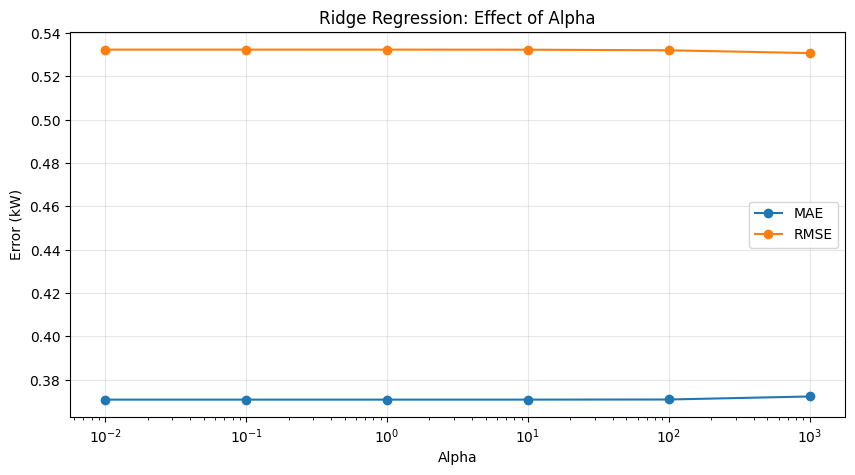

In [90]:
plt.figure(figsize=(10, 5))

plt.plot(
    tuning_df["alpha"],
    tuning_df["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    tuning_df["alpha"],
    tuning_df["RMSE"],
    marker="o",
    label="RMSE"
)

plt.xscale("log")

plt.xlabel("Alpha")
plt.ylabel("Error (kW)")
plt.title("Ridge Regression: Effect of Alpha")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## Peak Demand Analysis

Evaluate Ridge regression performance during high-demand
periods, focusing on extreme consumption peaks,
systematic underprediction, and comparison against
naive forecasting baselines.

In [91]:
peak_analysis = comparison.copy()

# Calculate signed residuals
peak_analysis["ridge_residual"] = (
    peak_analysis["target_kw"] -
    peak_analysis["ridge"]
)

# Select the 10 highest actual demand observations
top_10_peaks = peak_analysis.nlargest(
    10, "target_kw"
)

top_10_peaks[
    [
        "target_kw",
        "ridge",
        "lag_1",
        "lag_24",
        "lag_168",
        "ridge_residual"
    ]
]

,target_kw,ridge,lag_1,lag_24,lag_168,ridge_residual
timestamp,,,,,,
2009-02-11 18:00:00,5.233800,1.409692,1.013400,1.303867,2.542400,3.824108
2009-04-12 21:00:00,5.133967,3.807736,5.098300,2.738933,1.259500,1.326230
2009-11-22 20:00:00,5.115167,3.370972,3.818933,3.538233,2.040500,1.744195
2009-04-12 20:00:00,5.098300,2.652599,2.653167,4.145133,2.183467,2.445701
2009-01-24 11:00:00,5.073400,1.828355,1.861733,1.592900,1.516567,3.245045
2009-01-31 17:00:00,5.072500,2.899238,3.407433,3.019767,1.065167,2.173262
2009-01-18 21:00:00,4.860700,3.208421,3.606900,3.665800,3.503933,1.652279
2009-11-03 20:00:00,4.830833,3.507037,4.125833,2.753667,2.055633,1.323796
2009-02-22 17:00:00,4.829433,2.852971,3.718800,0.506933,0.357133,1.976462


### Visualize our peak predictions

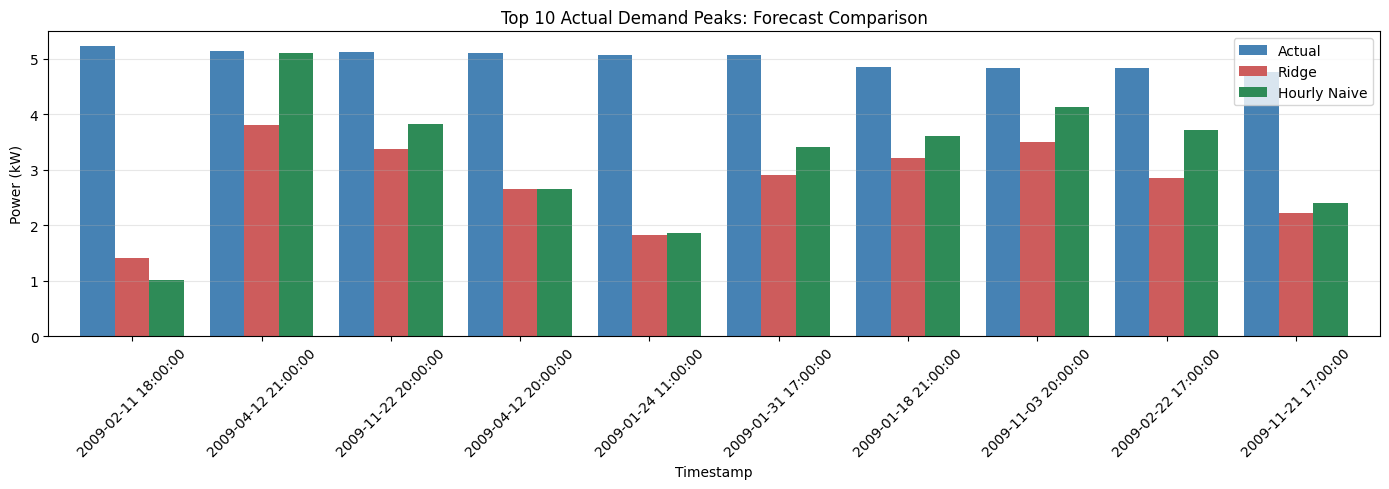

In [92]:
top_10_peaks[
    ["target_kw", "ridge", "lag_1"]
].plot(
    kind="bar",
    figsize=(14, 5),
    width=0.8,
    color=["steelblue", "indianred", "seagreen"]
)

plt.title("Top 10 Actual Demand Peaks: Forecast Comparison")
plt.xlabel("Timestamp")
plt.ylabel("Power (kW)")
plt.legend(["Actual", "Ridge", "Hourly Naive"])
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Calculate peak-specific performance

In [93]:
peak_results = []

for model in ["ridge", "lag_1", "lag_24", "lag_168"]:

    actual = top_10_peaks["target_kw"]
    predicted = top_10_peaks[model]

    residuals = actual - predicted

    peak_results.append({
        "Model": model,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Mean Residual": residuals.mean(),
        "Underpredicted Peaks": (residuals > 0).sum()
    })

peak_results_df = pd.DataFrame(peak_results)

peak_results_df.sort_values("MAE")

,Model,MAE,RMSE,Mean Residual,Underpredicted Peaks
1,lag_1,1.830477,2.178000,1.830477,10
0,ridge,2.225080,2.355818,2.225080,10
2,lag_24,2.571140,2.814814,2.571140,10
3,lag_168,3.050600,3.188024,3.050600,10


### Expand analysis to the top 5%

In [94]:
# Find the 95th percentile of actual demand
peak_threshold = peak_analysis["target_kw"].quantile(0.95)

# Select high-demand observations
high_demand = peak_analysis[
    peak_analysis["target_kw"] >= peak_threshold
].copy()

print("High-demand threshold:", peak_threshold)
print("High-demand observations:", len(high_demand))
print("Total validation observations:", len(peak_analysis))

High-demand threshold: 2.737089999999999
High-demand observations: 407
Total validation observations: 8124


### Calculate performance during high demand

In [95]:
high_demand_results = []

for model in ["ridge", "lag_1", "lag_24", "lag_168"]:

    actual = high_demand["target_kw"]
    predicted = high_demand[model]

    residuals = actual - predicted

    high_demand_results.append({
        "Model": model,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Mean Residual": residuals.mean(),
        "Underprediction Rate (%)": (
            (residuals > 0).mean() * 100
        )
    })

high_demand_results_df = pd.DataFrame(
    high_demand_results
)

high_demand_results_df.sort_values("MAE")

,Model,MAE,RMSE,Mean Residual,Underprediction Rate (%)
0,ridge,1.105884,1.308388,1.025973,89.680590
1,lag_1,1.139414,1.379434,0.871905,78.869779
3,lag_168,1.560551,1.842291,1.384659,88.452088
2,lag_24,1.634815,1.904740,1.511210,90.909091


## Residual Analysis

Investigate systematic overprediction and underprediction
across different demand levels and identify remaining
limitations of the Ridge forecasting model.

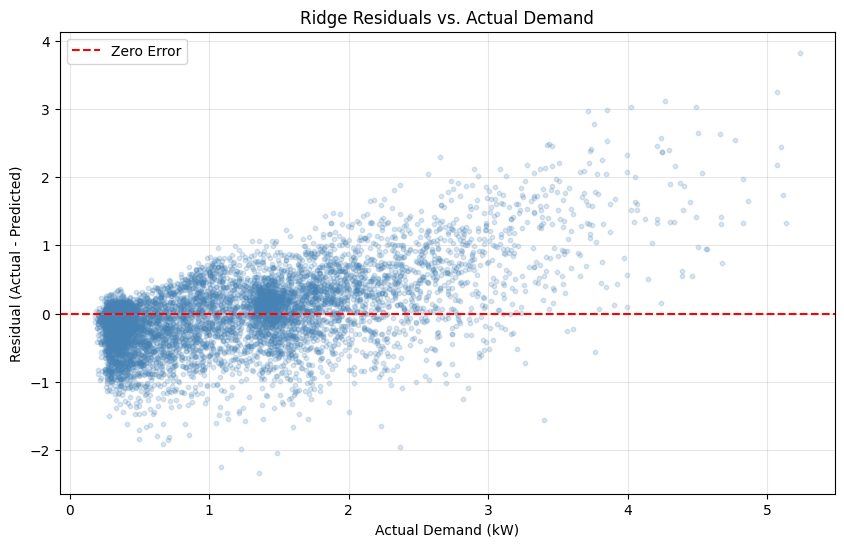

In [96]:
plt.figure(figsize=(10, 6))

plt.scatter(
    peak_analysis["target_kw"],
    peak_analysis["ridge_residual"],
    alpha=0.2,
    s=10,
    color="steelblue"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Actual Demand (kW)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Ridge Residuals vs. Actual Demand")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [97]:
peak_analysis["demand_group"] = pd.qcut(
    peak_analysis["target_kw"],
    q=5,
    labels=[
        "Very Low",
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

residual_summary = (
    peak_analysis
    .groupby("demand_group", observed=True)
    .agg(
        observations=("target_kw", "size"),
        mean_actual=("target_kw", "mean"),
        mean_predicted=("ridge", "mean"),
        mean_residual=("ridge_residual", "mean")
    )
)

residual_summary

,observations,mean_actual,mean_predicted,mean_residual
demand_group,,,,
Very Low,1625,0.295046,0.472056,-0.177010
Low,1625,0.402821,0.621750,-0.218929
Medium,1624,0.835857,0.983286,-0.147429
High,1626,1.458611,1.431805,0.026807
Very High,1624,2.425284,1.918907,0.506377


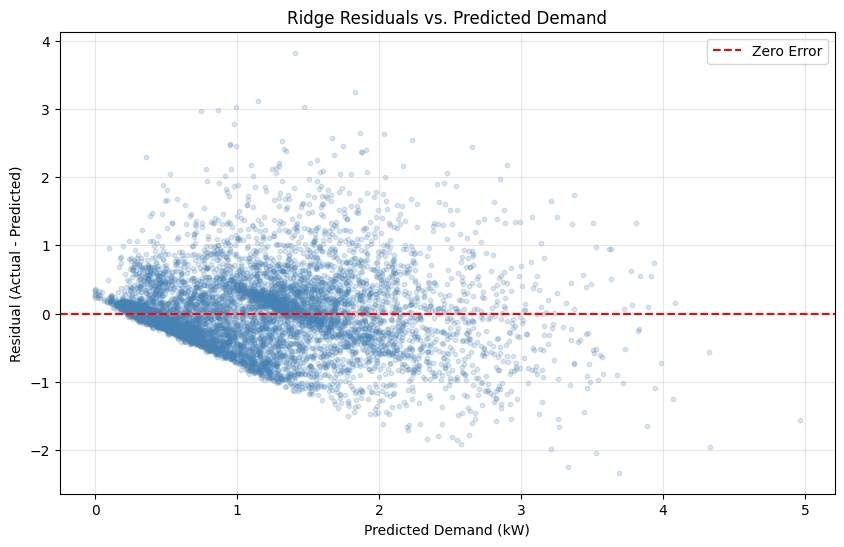

Overall mean residual: -0.002077936411890063


In [98]:
plt.figure(figsize=(10, 6))

plt.scatter(
    peak_analysis["ridge"],
    peak_analysis["ridge_residual"],
    alpha=0.2,
    s=10,
    color="steelblue"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Predicted Demand (kW)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Ridge Residuals vs. Predicted Demand")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(
    "Overall mean residual:",
    peak_analysis["ridge_residual"].mean()
)